# Bài 2 (Trang 28) - Dữ liệu Bank Marketing
## Câu 5: Thống kê số lần liên hệ (campaign, previous) và khảo sát sự liên quan với khả năng đăng ký

**Sinh viên:** Trần Đình Võ - **MSSV:** 6451071088

In [1]:
HO_TEN = "Trần Đình Võ"
MSSV = "6451071088"
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")

Họ tên: Trần Đình Võ - MSSV: 6451071088


### Import thư viện và đọc dữ liệu

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

df = pd.read_csv("../Dataset/bank/bank.csv", sep=";")

### Các bước xử lý của câu 1 → 4 (chuẩn bị dữ liệu)

In [3]:
# Trong bộ dữ liệu, giá trị thiếu được ghi là 'unknown' -> chuyển về NaN
df = df.replace("unknown", np.nan)

df["subscribed"] = (df["y"] == "yes").astype(int)

### Câu 5: Thống kê số lần liên hệ (campaign, previous) và khảo sát sự liên quan với khả năng đăng ký

In [4]:
df["contacts"] = df["campaign"] + df["previous"]          # tổng số lần liên hệ
df["contacted_before"] = (df["previous"] > 0).astype(int)  # đã từng được liên hệ ở chiến dịch trước

In [5]:
print("Số khách hàng chưa từng được liên hệ trước đó:", (df["contacted_before"] == 0).sum())
print("Số khách hàng đã từng được liên hệ:", (df["contacted_before"] == 1).sum())
df["campaign"].value_counts().sort_index().head(15)

Số khách hàng chưa từng được liên hệ trước đó: 3705
Số khách hàng đã từng được liên hệ: 816


campaign
1     1734
2     1264
3      558
4      325
5      167
6      155
7       75
8       56
9       30
10      27
11      22
12      21
13      17
14      10
15       9
Name: count, dtype: int64

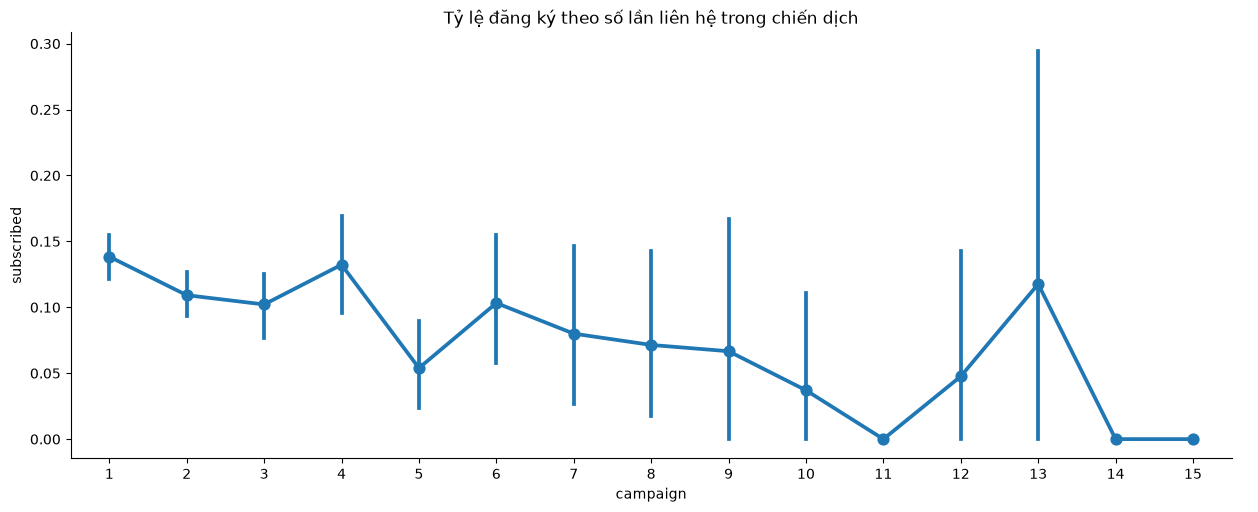

In [6]:
sns.catplot(x="campaign", y="subscribed", data=df[df["campaign"] <= 15], kind="point", aspect=2.5)
plt.title("Tỷ lệ đăng ký theo số lần liên hệ trong chiến dịch")
plt.show()

In [7]:
df.groupby("contacted_before")["subscribed"].agg(["count", "mean"]).round(3)

,count,mean
contacted_before,,
0,3705,0.091
1,816,0.225


### Nhận xét
- Có 3705 khách hàng chưa từng được liên hệ trước đó, 816 khách hàng đã từng được liên hệ.
- Khách hàng đã từng được liên hệ có tỷ lệ đăng ký ~22.5%, cao gấp hơn 2 lần nhóm chưa từng liên hệ (~9.1%).
- Số lần liên hệ trong chiến dịch (campaign) càng nhiều thì tỷ lệ đăng ký càng giảm.